# Stage 3 · Two-stage detector -> classifier (TS1), and what remains if object locations were perfect (assignment 5.1)

Stage 1 is the **T1** single-class detector (trained with `01_baseline.ipynb`, `EXPERIMENT = "T1"`; its weights are an input here, nothing is retrained). Stage 2 is a crop classifier trained on train_core ground-truth crops.
The notebook runs in two parts that share the **same classifier and the same stage-1 detections**, so every number in it is comparable:

| Part | Boxes given to the classifier | Answers |
|---|---|---|
| **TS1** (stages 1-3) | the T1 detector's class-agnostic boxes | detection ceiling, two-stage mAP50, classification cost (does decoupling + a strong classifier beat the fused YOLO head?) |
| **5.1** (stages 4-6) | the *ground-truth* boxes (perfect locations) | mAP50 with perfect locations (A), held-out typing accuracy and confusion (B), real against perfect boxes (C) |

All logic lives in `auric.model` and `auric.evaluation`; the notebook is the protocol.

**TS1 rule (declared before the first run):** two-stage dev mAP50 >= D1 + its CI width (about 0.13) supports "decoupling plus a strong classifier beats the fused head"; within the noise band it does not. (First run: 0.080 dev / 0.076 val, so it did not.)

**5.1 expectations (declared before this notebook was run;** the earlier proxy was a ResNet-18 on 64 px tight crops, mAP50 0.376 val / ~0.40 dev**):**
* A is at least the proxy's 0.38 (stronger classifier, 3x context). **A above ~0.60** would mean typing is not the limit and the detector is; **A at or below ~0.45** would mean that even with perfect locations the five-way problem stays far below 0.75 on these labels.
* Emitting the second-best class (`emit_topk` 2) raises A over `emit_topk` 1, as it did for the detector; the size of that gain is a direct read-out of how confusable the types are.
* The classifier is better on Cargo and Box than on Flatbed, Tractor and Liquid (the rare, visually similar types).

**Integrity.** The classifier sees train_core only. Dev and val images are held out, so scoring them is not leakage. Nothing here selects a model on val.

In [1]:
cp -r /kaggle/input/datasets/shriramprajapati/versiont1-output/* /kaggle/working/

In [2]:
rm -rf /kaggle/working/src

In [3]:
import os
import sys
from pathlib import Path

RUNTIME = "kaggle"     # "kaggle" | "local"
EXPERIMENT = "TS1"     # the config that defines stage 1 inference, the classifier and the assembly
if RUNTIME == "kaggle":
    os.environ["CUDA_VISIBLE_DEVICES"] = "0"
    import shutil
    import subprocess
    SRC_INPUT = Path("/kaggle/input/datasets/shriramprajapati/src-01auric-ts1/auric")     # <-- the uploaded package (read-only)
    SRC_DIR = Path("/kaggle/working/src")
    shutil.copytree(SRC_INPUT, SRC_DIR / "auric", dirs_exist_ok=True, ignore=shutil.ignore_patterns("__pycache__"))
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics==8.4.179"], check=True)
    T1_WEIGHTS = Path("/kaggle/input/datasets/shriramprajapati/versiont1-output/work/runs/T1_s0/train/weights/last.pt")   # stage 1, trained earlier
elif RUNTIME == "local":
    SRC_DIR = Path("C:/Auric/src")
    T1_WEIGHTS = Path("C:/Auric/work/runs/T1_s0/train/weights/last.pt")
else:
    raise ValueError(f"unknown RUNTIME {RUNTIME!r}")
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))
CONFIG_FILE = SRC_DIR / "auric" / "configs" / f"{EXPERIMENT}.yaml"
ENV_FILE = SRC_DIR / "auric" / "configs" / "env" / f"{RUNTIME}.yaml"
assert T1_WEIGHTS.exists(), f"stage-1 weights not found: {T1_WEIGHTS} (attach the T1 output dataset or train T1 with 01_baseline.ipynb)"

# Run-time decisions (not part of the experiment config)
REUSE_CLASSIFIER = False     # True: load <OUT_DIR>/classifier.pt when it exists (e.g. after a kernel restart); False: always train
TOPK = (1, 2, 5)             # classes emitted per perfect box in 5.1; the config's `emit_topk` is the headline
OVERRIDES = ["two_stage.classifier.batch= 256"]               # e.g. ["two_stage.classifier.epochs=1"] for a smoke run

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 26.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 5.4 MB/s eta 0:00:00


In [4]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from auric.boxes import box_area, size_bucket_labels
from auric.config import load_config
from auric.data.dataset import index_split, load_annotations, read_class_names, read_image
from auric.data.splits import ensure_split, subset
from auric.evaluation import evaluate
from auric.evaluation.classification import classification_report, matched_pairs
from auric.model.classifier import CropClassifier, CropSpec, train_classifier
from auric.model.predict import TiledPredictor
from auric.model.two_stage import as_single_class, assemble, gt_as_detections, gt_single_class
from auric.structures import save_detections
from auric.visualize import CLASS_COLORS, crop_around, draw_boxes

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.precision", 3)

cfg = load_config(CONFIG_FILE, ENV_FILE, overrides=OVERRIDES)
DATA_ROOT, WORK_DIR, SPLIT_FILE = Path(cfg["paths"]["data_root"]), Path(cfg["paths"]["work_dir"]), Path(cfg["paths"]["split_file"])
DEVICE, WORKERS = cfg["runtime"]["device"], cfg["runtime"]["workers"]
OUT_DIR = WORK_DIR / "analysis" / "two_stage"          # everything this notebook writes
OUT_DIR.mkdir(parents=True, exist_ok=True)

NAMES = read_class_names(DATA_ROOT)
K = len(NAMES)
SHORT = [n.replace("Truck", "").replace("w/", "").strip() for n in NAMES]
RECORDS = {s: index_split(DATA_ROOT, s) for s in ("train", "val")}
ANNS = {s: load_annotations(RECORDS[s], K) for s in RECORDS}
split, _ = ensure_split(SPLIT_FILE, ANNS["train"], NAMES, **cfg["split"])
TRAIN_CORE = subset(RECORDS["train"], split["train_core"])
EVAL = {"dev": subset(RECORDS["train"], split["dev"]), "val": RECORDS["val"]}
GTS = {"dev": {r.image_id: ANNS["train"][r.image_id] for r in EVAL["dev"]},
       "val": {r.image_id: ANNS["val"][r.image_id] for r in EVAL["val"]}}
TS, EC = cfg["two_stage"], cfg["evaluation"]
ASM, CC = TS["assembly"], TS["classifier"]
print({p: (len(GTS[p]), sum(len(a) for a in GTS[p].values())) for p in GTS}, "(images, objects);", "train_core:", len(TRAIN_CORE), "images")

{'dev': (66, 1093), 'val': (22, 1552)} (images, objects); train_core: 377 images


## Stage 1 · Class-agnostic detections from the T1 detector

T1 is run with the class-agnostic merge (`inference.merge_agnostic`), so one truck is never split across classes before stage 2. Scoring these boxes with every class set to one id gives the **detection ceiling**: the best AP50 any classifier on top of them can reach.

In [5]:
predictor = TiledPredictor(T1_WEIGHTS, cfg["inference"], DEVICE)
STAGE1 = {p: predictor.predict(EVAL[p], desc=f"stage 1 {p}") for p in EC["splits"]}
CEIL = {p: evaluate(gt_single_class(GTS[p]), as_single_class(STAGE1[p]), ["truck"], EC["size_bins"], bootstrap=0) for p in EC["splits"]}
print("detection ceiling AP50:", {p: round(CEIL[p].summary["AP50_class_agnostic"], 4) for p in CEIL})

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


stage 1 dev:   0%|          | 0/66 [00:00<?, ?image/s]

stage 1 val:   0%|          | 0/22 [00:00<?, ?image/s]

detection ceiling AP50: {'dev': 0.3256, 'val': 0.3238}


## Stage 2 · The crop classifier (trained on train_core ground-truth crops only)

ConvNeXt-tiny (ImageNet init, not xView and not DOTA trucks), crops of 3x the object resized to 128 px, flips and 90-degree rotations, class-balanced cross-entropy, AdamW, cosine schedule, 20 epochs, seed 0 (`two_stage.classifier` in `TS1.yaml`).
One line is printed per epoch. The classifier is saved right after training, so a kernel restart does not cost a retraining (set `REUSE_CLASSIFIER = True`).

In [6]:
CLF_FILE = OUT_DIR / "classifier.pt"
if REUSE_CLASSIFIER and CLF_FILE.exists():
    clf = CropClassifier.load(CLF_FILE, DEVICE)
    print("loaded", CLF_FILE)
else:
    spec = CropSpec(context=CC["context"], min_px=CC["min_px"], out_px=CC["out_px"])
    clf = train_classifier(TRAIN_CORE, ANNS["train"], NAMES, spec, backbone=CC["backbone"], epochs=CC["epochs"], lr=CC["lr"],
                           batch=CC["batch"], class_balanced=CC["class_balanced"], device=DEVICE, workers=WORKERS,
                           seed=cfg["experiment"]["seed"])
    clf.save(CLF_FILE)
    print("saved", CLF_FILE)

Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth


100%|██████████| 109M/109M [00:00<00:00, 209MB/s] 


classifier convnext_tiny: 6525 crops, 25 batches of 256 per epoch, 20 epochs, lr 0.0003
epoch  1/20  loss 1.4162  train_acc 0.612  lr 3.00e-04     844s elapsed
epoch  2/20  loss 1.2382  train_acc 0.684  lr 2.98e-04    1658s elapsed
epoch  3/20  loss 1.1219  train_acc 0.721  lr 2.93e-04    2448s elapsed
epoch  4/20  loss 1.0015  train_acc 0.771  lr 2.84e-04    3253s elapsed
epoch  5/20  loss 0.9079  train_acc 0.799  lr 2.71e-04    4065s elapsed
epoch  6/20  loss 0.7962  train_acc 0.841  lr 2.56e-04    4879s elapsed
epoch  7/20  loss 0.7056  train_acc 0.877  lr 2.38e-04    5686s elapsed
epoch  8/20  loss 0.6394  train_acc 0.905  lr 2.18e-04    6503s elapsed
epoch  9/20  loss 0.5856  train_acc 0.922  lr 1.96e-04    7315s elapsed
epoch 10/20  loss 0.5395  train_acc 0.942  lr 1.73e-04    8131s elapsed
epoch 11/20  loss 0.5102  train_acc 0.952  lr 1.50e-04    8940s elapsed
epoch 12/20  loss 0.4865  train_acc 0.957  lr 1.27e-04    9741s elapsed
epoch 13/20  loss 0.4695  train_acc 0.967  lr 1.

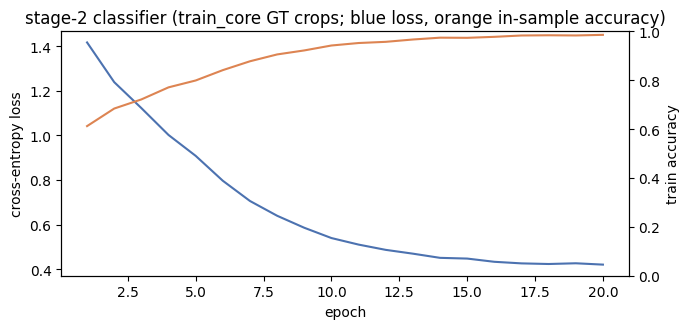

,loss,train_acc,lr
epoch,,,
1,1.416,0.612,3.000e-04
2,1.238,0.684,3.000e-04
3,1.122,0.721,3.000e-04
4,1.002,0.771,3.000e-04
5,0.908,0.799,3.000e-04
6,0.796,0.841,3.000e-04
7,0.706,0.877,2.000e-04
8,0.639,0.905,2.000e-04
9,0.586,0.922,2.000e-04


In [7]:
hist = pd.DataFrame(clf.history).set_index("epoch")
fig, ax1 = plt.subplots(figsize=(7, 3.4))
ax1.plot(hist.index, hist.loss, color="#4c72b0")
ax1.set(xlabel="epoch", ylabel="cross-entropy loss")
ax2 = ax1.twinx()
ax2.plot(hist.index, hist.train_acc, color="#dd8452")
ax2.set(ylabel="train accuracy", ylim=(0, 1))
ax1.set_title("stage-2 classifier (train_core GT crops; blue loss, orange in-sample accuracy)")
fig.tight_layout()
plt.show()
display(hist.round(4))

## Stage 3 · TS1 result: detection ceiling, two-stage mAP50, classification cost

Stage 1 boxes are re-labelled by the classifier (`assemble`): final score = detector score^alpha * class probability^(1-alpha), and the `emit_topk` most likely classes of each box are emitted as separate detections (the metric can only credit a class it sees).
`classification cost = detection ceiling - two-stage mAP50`. The two-stage detections are saved in the layout of a run's predictions (they feed `06_results_table.ipynb`).

In [8]:
FINAL = {p: assemble(STAGE1[p], EVAL[p], clf, alpha=ASM["alpha"], emit_topk=ASM["emit_topk"], workers=WORKERS) for p in EC["splits"]}
REAL = {p: evaluate(GTS[p], FINAL[p], NAMES, EC["size_bins"], EC["bootstrap"], EC["seed"]) for p in EC["splits"]}
for p in EC["splits"]:
    save_detections(FINAL[p], OUT_DIR / "TS1_s0" / "predictions" / f"{p}.csv.gz")

display(pd.DataFrame({p: {
    "detection ceiling (agnostic AP50)": CEIL[p].summary["AP50_class_agnostic"],
    "two-stage mAP50": REAL[p].summary["mAP50"],
    "classification cost": CEIL[p].summary["AP50_class_agnostic"] - REAL[p].summary["mAP50"],
    "mAP50 CI95": f"[{REAL[p].summary['mAP50_ci95'][0]:.3f}, {REAL[p].summary['mAP50_ci95'][1]:.3f}]"} for p in EC["splits"]}))
for p in EC["splits"]:
    print(p)
    display(REAL[p].per_class.set_index("class")[["n_images", "n_gt", "AP50", "AP50_lo", "AP50_hi", "AP75", "recall_max"]])

stage2 classify:   0%|          | 0/189 [00:00<?, ?batch/s]

stage2 classify:   0%|          | 0/107 [00:00<?, ?batch/s]

,dev,val
detection ceiling (agnostic AP50),0.326,0.324
two-stage mAP50,0.08,0.098
classification cost,0.245,0.225
mAP50 CI95,"[0.053, 0.122]","[0.064, 0.153]"


dev


,n_images,n_gt,AP50,AP50_lo,AP50_hi,AP75,recall_max
class,,,,,,,
Cargo Truck,55,533,0.098,0.059,0.154,0.031,0.745
Truck w/Box,39,346,0.255,0.111,0.442,0.146,0.734
Truck w/Flatbed,30,106,0.029,0.012,0.086,0.017,0.340
Truck Tractor,18,77,0.010,0.003,0.052,0.005,0.403
Truck w/Liquid,15,31,0.009,0.002,0.035,0.004,0.323


val


,n_images,n_gt,AP50,AP50_lo,AP50_hi,AP75,recall_max
class,,,,,,,
Cargo Truck,19,800,0.136,7.084e-02,0.203,2.924e-02,0.710
Truck w/Box,17,493,0.190,4.348e-02,0.323,6.939e-02,0.698
Truck w/Flatbed,14,122,0.109,2.991e-02,0.256,2.120e-02,0.508
Truck Tractor,11,117,0.007,7.201e-04,0.024,4.664e-04,0.316
Truck w/Liquid,8,20,0.050,3.724e-04,0.208,4.901e-02,0.550


## Stage 4 · 5.1 (A): perfect locations scored by the real evaluator

**Question.** Suppose the location of every labelled object were known exactly: how much of the five-class problem remains?

Every labelled box becomes a stage-1 detection with objectness 1 (`gt_as_detections`), the classifier types it, and `evaluate` scores the result exactly as it scores a detector (COCO-101 AP50 per class, mean over the five classes, image bootstrap).
There are no missed objects, no background detections and no localisation error, so what is left is the five-way typing problem as the metric sees it. `emit_topk` k emits the k most likely classes per box: with k = 1 a wrong type is both a miss for the true class and a false positive for the predicted one;
with larger k the metric can credit the true class at a lower score.

In [9]:
PERFECT = {}
for part in EC["splits"]:
    boxes = gt_as_detections(GTS[part])
    for k in TOPK:
        final = assemble(boxes, EVAL[part], clf, alpha=ASM["alpha"], emit_topk=k, workers=WORKERS)
        PERFECT[(part, k)] = evaluate(GTS[part], final, NAMES, EC["size_bins"], EC["bootstrap"], EC["seed"])

rows = []
for (part, k), rep in PERFECT.items():
    ci = rep.summary["mAP50_ci95"]
    rows.append({"split": part, "emit_topk": k, "mAP50": rep.summary["mAP50"], "CI95": f"[{ci[0]:.3f}, {ci[1]:.3f}]",
                 **dict(zip(SHORT, rep.per_class.set_index("class").AP50.reindex(NAMES)))})
PERFECT_TABLE = pd.DataFrame(rows)
display(PERFECT_TABLE.round(3))
HEAD_K = ASM["emit_topk"]

stage2 classify:   0%|          | 0/5 [00:00<?, ?batch/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7aa4665f6c00>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7aa4665f6c00>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

stage2 classify:   0%|          | 0/5 [00:00<?, ?batch/s]

stage2 classify:   0%|          | 0/5 [00:00<?, ?batch/s]

stage2 classify:   0%|          | 0/7 [00:00<?, ?batch/s]

stage2 classify:   0%|          | 0/7 [00:00<?, ?batch/s]

stage2 classify:   0%|          | 0/7 [00:00<?, ?batch/s]

,split,emit_topk,mAP50,CI95,Cargo,Box,Flatbed,Tractor,Liquid
0,dev,1,0.233,"[0.188, 0.289]",0.548,0.351,0.026,0.203,0.040
1,dev,2,0.292,"[0.243, 0.349]",0.616,0.434,0.058,0.295,0.055
2,dev,5,0.361,"[0.317, 0.411]",0.698,0.553,0.132,0.342,0.078
3,val,1,0.291,"[0.216, 0.371]",0.496,0.404,0.183,0.232,0.139
4,val,2,0.358,"[0.279, 0.444]",0.611,0.482,0.251,0.298,0.149
5,val,5,0.421,"[0.344, 0.500]",0.699,0.583,0.302,0.358,0.162


## Stage 5 · 5.1 (B): how often is the type wrong, and which types are confused (held-out ground-truth crops)

Accuracy alone is not interpretable here: always answering "Cargo Truck" scores the majority share, so the chance levels sit next to the accuracies. Balanced accuracy (mean per-class recall) is the fair summary under imbalance.
The size split shows whether typing degrades for small objects (fewer pixels to see the bed or the trailer) or is just as poor for large ones (then the problem is the labels and examples, not the resolution).

In [10]:
TYPED = {}     # part -> dict(y, proba, image_id, box)
for part in EC["splits"]:
    ids = [i for i in GTS[part] if len(GTS[part][i])]
    by_img = {i: GTS[part][i].boxes for i in ids}
    proba = clf.predict_proba(EVAL[part], by_img, workers=WORKERS)
    TYPED[part] = {"y": np.concatenate([GTS[part][i].cls for i in ids]), "proba": np.concatenate([proba[i] for i in ids]),
                   "image_id": np.concatenate([[i] * len(GTS[part][i]) for i in ids]),
                   "box": np.concatenate([GTS[part][i].boxes for i in ids])}
REPORT = {p: classification_report(t["y"], t["proba"], NAMES) for p, t in TYPED.items()}

display(pd.DataFrame({p: {"objects": r["n"], "accuracy": r["accuracy"], "balanced accuracy": r["balanced_accuracy"], "top-2 accuracy": r["top2_accuracy"],
                          "chance (always the majority class)": r["chance_majority"], "chance (balanced)": r["chance_balanced"]} for p, r in REPORT.items()}).round(3))
for p, r in REPORT.items():
    print(p)
    display(r["per_class"].round(3))

stage2 classify:   0%|          | 0/5 [00:00<?, ?batch/s]

Exception ignored in: Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7aa4665f6c00>
<function _MultiProcessingDataLoaderIter.__del__ at 0x7aa4665f6c00>
Traceback (most recent call last):
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    Exception ignored in:     self._shutdown_workers()self._shutdown_workers()<function _MultiProcessingDataLoaderIter.__del__ at 0x7aa4665f6c00>
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers


  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
Traceback (most recent call last):
      File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
        if w.is_alive():if w

stage2 classify:   0%|          | 0/7 [00:00<?, ?batch/s]

can only test a child processassert self._parent_pid == os.getpid(), 'can only test a child process'

AssertionError: can only test a child process


,dev,val
objects,1093.000,1552.000
accuracy,0.569,0.581
balanced accuracy,0.348,0.408
top-2 accuracy,0.726,0.764
chance (always the majority class),0.488,0.515
chance (balanced),0.200,0.200


dev


,support,predicted,precision,recall,F1
class,,,,,
Cargo Truck,533,609,0.654,0.747,0.697
Truck w/Box,346,336,0.557,0.540,0.548
Truck w/Flatbed,106,73,0.178,0.123,0.145
Truck Tractor,77,51,0.451,0.299,0.359
Truck w/Liquid,31,24,0.042,0.032,0.036


val


,support,predicted,precision,recall,F1
class,,,,,
Cargo Truck,800,818,0.658,0.672,0.665
Truck w/Box,493,532,0.534,0.576,0.554
Truck w/Flatbed,122,108,0.407,0.361,0.383
Truck Tractor,117,73,0.452,0.282,0.347
Truck w/Liquid,20,21,0.143,0.150,0.146


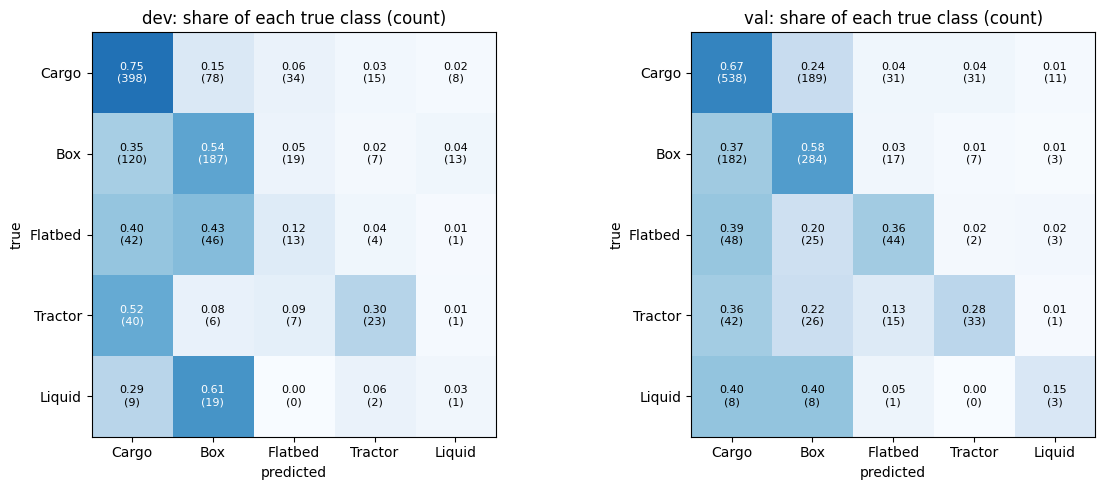

,split,size,objects,accuracy,balanced accuracy
0,dev,"s [16,32)",517,0.476,0.270
1,dev,"m [32,inf)",243,0.609,0.229
2,dev,"xs [0,16)",333,0.685,0.285
3,val,"s [16,32)",818,0.540,0.433
4,val,"m [32,inf)",471,0.605,0.347
5,val,"xs [0,16)",263,0.665,0.253


In [11]:
fig, axes = plt.subplots(1, len(REPORT), figsize=(6.2 * len(REPORT), 5))
for ax, (p, r) in zip(np.atleast_1d(axes), REPORT.items()):
    conf = r["confusion"].to_numpy()
    norm = conf / np.maximum(conf.sum(1, keepdims=True), 1)
    ax.imshow(norm, cmap="Blues", vmin=0, vmax=1)
    for i in range(K):
        for j in range(K):
            ax.text(j, i, f"{norm[i, j]:.2f}\n({conf[i, j]})", ha="center", va="center", fontsize=8, color="white" if norm[i, j] > 0.5 else "black")
    ax.set(xticks=range(K), yticks=range(K), xticklabels=SHORT, yticklabels=SHORT, xlabel="predicted", ylabel="true", title=f"{p}: share of each true class (count)")
plt.tight_layout()
plt.show()

rows = []
for p, t in TYPED.items():
    side = np.sqrt(box_area(t["box"]))
    bucket = size_bucket_labels(side, EC["size_bins"])
    for b in dict.fromkeys(bucket):
        m = bucket == b
        rep = classification_report(t["y"][m], t["proba"][m], NAMES)
        rows.append({"split": p, "size": b, "objects": int(m.sum()), "accuracy": rep["accuracy"], "balanced accuracy": rep["balanced_accuracy"]})
display(pd.DataFrame(rows).round(3))

### Typing failures, shown (val): the most confident wrong types, and some correct ones for contrast

Crops are 3x the object. Each caption is `true -> predicted (probability of the predicted class)`. Read them for what the label could be asking: is the object really ambiguous between the two types, or is it clearly one and the classifier wrong?

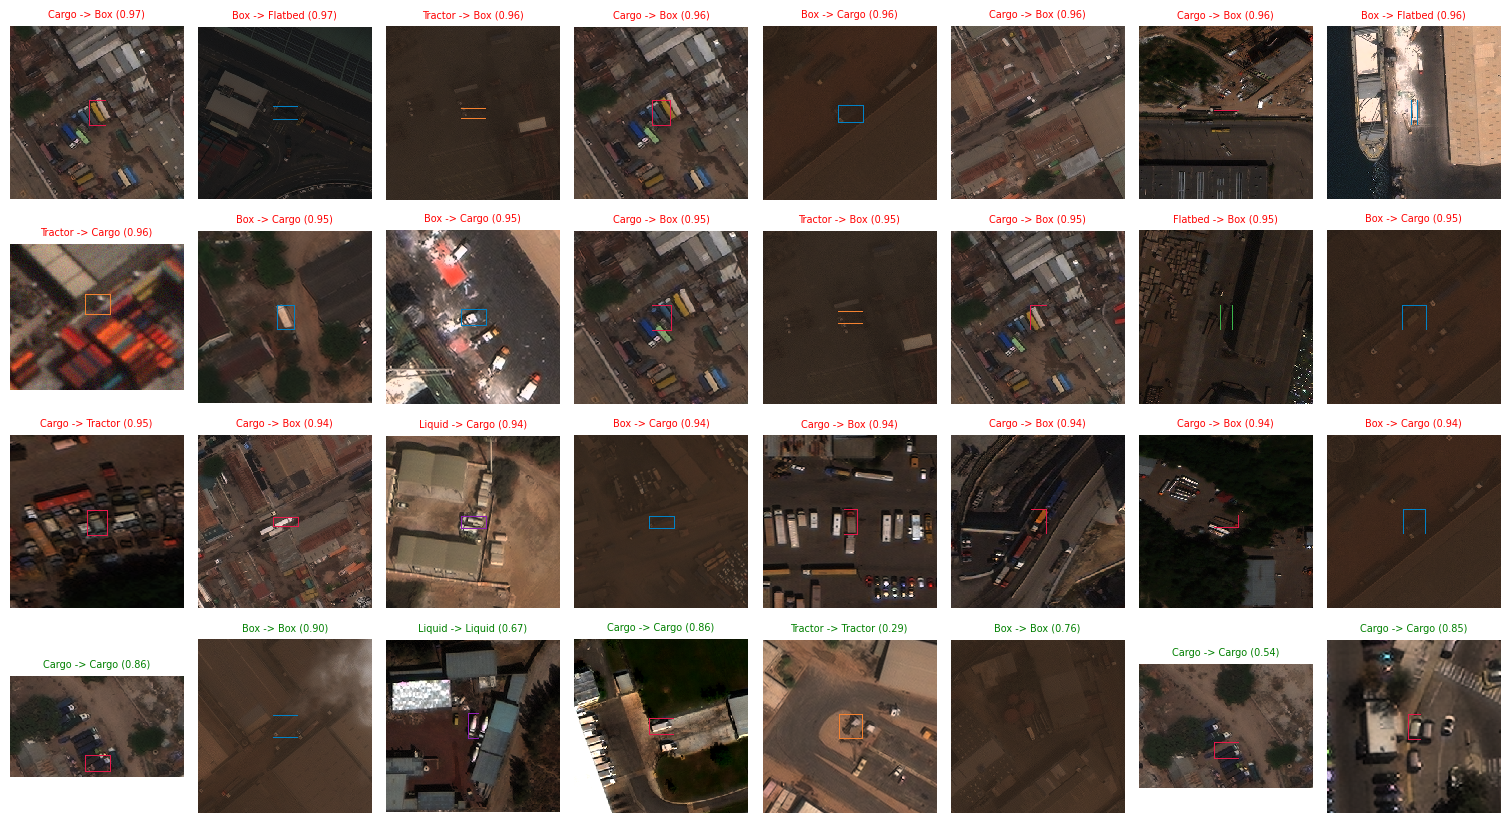

In [12]:
t = TYPED["val"]
pred, conf = t["proba"].argmax(1), t["proba"].max(1)
wrong = np.flatnonzero(pred != t["y"])
wrong = wrong[np.argsort(-conf[wrong])][:24]
right = np.flatnonzero(pred == t["y"])
right = right[np.random.default_rng(0).permutation(len(right))[:8]]
path = {r.image_id: r.image_path for r in EVAL["val"]}
items = [(i, "wrong") for i in wrong] + [(i, "right") for i in right]
cols = 8
rows_n = int(np.ceil(len(items) / cols))
fig, axes = plt.subplots(rows_n, cols, figsize=(cols * 1.9, rows_n * 2.1), squeeze=False)
for ax in axes.flat:
    ax.axis("off")
cache = {}
for ax, (i, kind) in zip(axes.flat, items):
    img = cache.setdefault(t["image_id"][i], np.ascontiguousarray(read_image(path[t["image_id"][i]])[:, :, ::-1]))
    c, (x0, y0) = crop_around(img, t["box"][i], 3.0)
    c = draw_boxes(c, [np.subtract(t["box"][i], [x0, y0, x0, y0])], [CLASS_COLORS[t["y"][i]]], 1)
    ax.imshow(c, interpolation="nearest")
    ax.set_title(f"{SHORT[t['y'][i]]} -> {SHORT[pred[i]]} ({conf[i]:.2f})", fontsize=7, color="red" if kind == "wrong" else "green")
plt.tight_layout()
plt.show()

## Stage 6 · 5.1 (C): real boxes against perfect boxes, with the same classifier

1. **The decomposition.** Detection ceiling (class-agnostic AP50 of the stage-1 boxes) / mAP50 with perfect boxes (A) / the real two-stage mAP50 of Stage 3. The gap between A and the real two-stage score is what real locations, missed objects and background detections cost *given this classifier*.
2. **Does localisation noise change the type?** For every labelled object that a stage-1 box finds (IoU >= 0.5, score >= the operating point of the class-agnostic evaluation), the classifier types the *detector's* box and the *ground-truth* box of that same object. If the two agree, the type error is not caused by where the box is.

In [13]:
DECOMP = pd.DataFrame({p: {
    "detection ceiling (agnostic AP50, stage-1 boxes)": CEIL[p].summary["AP50_class_agnostic"],
    f"A: perfect boxes, emit_topk {HEAD_K}": PERFECT[(p, HEAD_K)].summary["mAP50"],
    f"real two-stage mAP50 (emit_topk {HEAD_K})": REAL[p].summary["mAP50"],
    "typing error left with perfect boxes (1 - A)": 1 - PERFECT[(p, HEAD_K)].summary["mAP50"],
    "cost of real locations given this classifier (A - real)": PERFECT[(p, HEAD_K)].summary["mAP50"] - REAL[p].summary["mAP50"],
} for p in EC["splits"]})
display(DECOMP.round(3))
display(pd.concat({p: REAL[p].per_class.set_index("class").AP50.rename("real two-stage AP50").to_frame().join(
    PERFECT[(p, HEAD_K)].per_class.set_index("class").AP50.rename("perfect-box AP50")) for p in EC["splits"]}, axis=1).round(3))

,dev,val
"detection ceiling (agnostic AP50, stage-1 boxes)",0.326,0.324
"A: perfect boxes, emit_topk 2",0.292,0.358
real two-stage mAP50 (emit_topk 2),0.080,0.098
typing error left with perfect boxes (1 - A),0.708,0.642
cost of real locations given this classifier (A - real),0.211,0.260


dev                                  val                 
                real two-stage AP50 perfect-box AP50 real two-stage AP50 perfect-box AP50
class                                                                                    
Cargo Truck                   0.098            0.616               0.136            0.611
Truck w/Box                   0.255            0.434               0.190            0.482
Truck w/Flatbed               0.029            0.058               0.109            0.251
Truck Tractor                 0.010            0.295               0.007            0.298
Truck w/Liquid                0.009            0.055               0.050            0.149

In [14]:
rows = []
for p in EC["splits"]:
    conf_star = CEIL[p].summary["operating_point"]["conf"]
    by_det, by_gt, y = {}, {}, []
    for r in EVAL[p]:
        d, g = STAGE1[p].get(r.image_id), GTS[p][r.image_id]
        if d is None or len(d) == 0 or len(g) == 0:
            continue
        keep = d.scores >= conf_star
        pairs = matched_pairs(d.boxes[keep], d.scores[keep], g)
        if len(pairs):
            by_det[r.image_id] = d.boxes[keep][pairs[:, 0]]
            by_gt[r.image_id] = g.boxes[pairs[:, 1]]
            y.append(g.cls[pairs[:, 1]])
    ids = list(by_det)
    pd_, pg_ = (clf.predict_proba(EVAL[p], b, workers=WORKERS) for b in (by_det, by_gt))
    y = np.concatenate(y)
    pd_, pg_ = np.concatenate([pd_[i] for i in ids]), np.concatenate([pg_[i] for i in ids])
    rd, rg = classification_report(y, pd_, NAMES), classification_report(y, pg_, NAMES)
    rows.append({"split": p, "objects found": len(y), "conf*": f"{conf_star:.3f}",
                 "accuracy (detector box)": rd["accuracy"], "accuracy (GT box)": rg["accuracy"],
                 "balanced acc (detector box)": rd["balanced_accuracy"], "balanced acc (GT box)": rg["balanced_accuracy"],
                 "same type from both boxes": float((pd_.argmax(1) == pg_.argmax(1)).mean())})
display(pd.DataFrame(rows).set_index("split").round(3))

stage2 classify:   0%|          | 0/2 [00:00<?, ?batch/s]

stage2 classify:   0%|          | 0/2 [00:00<?, ?batch/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7aa4665f6c00>Exception ignored in: 
Traceback (most recent call last):
<function _MultiProcessingDataLoaderIter.__del__ at 0x7aa4665f6c00>Exception ignored in: 
Traceback (most recent call last):
<function _MultiProcessingDataLoaderIter.__del__ at 0x7aa4665f6c00>  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__

    Traceback (most recent call last):
    self._shutdown_workers()self._shutdown_workers()  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers

Exception ignored in:       File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    se

stage2 classify:   0%|          | 0/3 [00:00<?, ?batch/s]

stage2 classify:   0%|          | 0/3 [00:00<?, ?batch/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7aa4665f6c00>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Traceback (most recent call last):
  File "/usr/lib/python3.13/multiprocessing/queues.py", line 257, in _feed
    reader_close()
    ~~~~~~~~~~~~^^
  File "/usr/lib/python3.13/multiprocessing/connection.py", line 183, in close
    self._close()
    ~~~~~~~~~~~^^
  File "/usr/lib/python3.13/multiprocessing/connection.py", line 382, in _close
    _close(self._handle)
    ~~~~~~^^^^^^^^^^^^^^
OSError: [Errno

,objects found,conf*,accuracy (detector box),accuracy (GT box),balanced acc (detector box),balanced acc (GT box),same type from both boxes
split,,,,,,,
dev,455,0.172,0.580,0.567,0.374,0.351,0.866
val,612,0.164,0.588,0.609,0.406,0.421,0.869


## Stage 7 · Save the numbers

Tables are written next to the classifier so the report is built from files, not from this notebook's screen.

In [15]:
PERFECT_TABLE.to_csv(OUT_DIR / "perfect_location_map50.csv", index=False)
for (p, k), rep in PERFECT.items():
    if k == HEAD_K:
        rep.per_class.to_csv(OUT_DIR / f"perfect_location_per_class_{p}.csv", index=False)
for p, r in REPORT.items():
    r["per_class"].to_csv(OUT_DIR / f"typing_per_class_{p}.csv")
    r["confusion"].to_csv(OUT_DIR / f"typing_confusion_{p}.csv")
for p in EC["splits"]:
    REAL[p].per_class.to_csv(OUT_DIR / f"ts1_per_class_{p}.csv", index=False)
DECOMP.to_csv(OUT_DIR / "decomposition.csv")
(OUT_DIR / "summary.json").write_text(json.dumps({
    "classifier": {"backbone": clf.backbone, "spec": clf.spec.__dict__, "epochs": len(clf.history or []), "seed": cfg["experiment"]["seed"],
                   "final_train_acc": clf.history[-1]["train_acc"] if clf.history else None},
    "stage1_weights": str(T1_WEIGHTS),
    "detection_ceiling_AP50": {p: CEIL[p].summary["AP50_class_agnostic"] for p in CEIL},
    "ts1_mAP50": {p: REAL[p].summary["mAP50"] for p in REAL},
    "perfect_location_mAP50": {f"{p}_k{k}": r.summary["mAP50"] for (p, k), r in PERFECT.items()},
    "typing": {p: {k: r[k] for k in ("n", "accuracy", "balanced_accuracy", "top2_accuracy", "chance_majority", "chance_balanced")} for p, r in REPORT.items()}}, indent=1))
print(sorted(str(f.relative_to(OUT_DIR)) for f in OUT_DIR.rglob("*") if f.is_file()))

['TS1_s0/predictions/dev.csv.gz', 'TS1_s0/predictions/val.csv.gz', 'classifier.pt', 'decomposition.csv', 'perfect_location_map50.csv', 'perfect_location_per_class_dev.csv', 'perfect_location_per_class_val.csv', 'summary.json', 'ts1_per_class_dev.csv', 'ts1_per_class_val.csv', 'typing_confusion_dev.csv', 'typing_confusion_val.csv', 'typing_per_class_dev.csv', 'typing_per_class_val.csv']


## Observations (fill in after the run)

**TS1**
* Detection ceiling, two-stage mAP50 and classification cost (dev, val, CI); against the declared rule (>= D1 + CI width) and D1 (0.101 dev / 0.088 val); against the first TS1 run (0.080 / 0.076) as a check that the retrained classifier reproduces it.
* Per-class AP50: where the two-stage design helps or hurts compared with the fused head (D1).

**5.1**
* **How much of the five-class problem remains (A, B):** mAP50 with perfect boxes (dev, val, with CI) against the pre-declared 0.45 / 0.60 thresholds and the 0.75 target; balanced accuracy against the 0.20 chance level and the majority share; what `emit_topk` 2 and 5 add.
* **Where it remains:** per-class recall and AP50, the confusion pairs that carry the error (Cargo <-> Box? Flatbed -> Cargo? Tractor?), whether small objects are typed worse than large ones.
* **Is it the classifier or the labels?** The in-sample accuracy (see the curve) against the held-out accuracy; whether the confidently wrong crops look ambiguous or plainly mislabelled.
* **Real against perfect boxes (C):** the decomposition; whether the detector's boxes change the type (agreement between detector-box and GT-box typing).
* **What the experiment cannot establish.**
  * *Ambiguity versus inability.* A held-out error against the labels mixes a classifier that is too weak with labels that are inconsistent (each xView labeller worked on one general category and typed an instance only when confident). Bayes error is unknown; a human relabelling of a blinded val sample is the missing control.
  * *One classifier family, one context size, one seed, 20 epochs.* A better classifier, other crop contexts or more epochs could move the number; the earlier ResNet-18 proxy and this one bracket it, they do not bound it.
  * *Perfect locations of the labelled objects only.* Unlabelled trucks (the dominant source of false positives on dev) are not part of this world, so the real problem is harder than A suggests in a way A cannot measure.
  * *The labels as reference.* Ground-truth boxes are annotator boxes, not exact; "perfect" means "as annotated".
  * *Rare classes.* Val has 20 Liquid objects (8 images) and 117 Tractor objects (11 images); their per-class numbers carry wide intervals.
  * *Scene overlap.* The classifier is held out by image, but objects of one scene share conditions (sensor, haze, a depot's trucks); a test object may have near-duplicates in the training scenes of the same depot.

Record the TS1 numbers and the 5.1 numbers as entries in `exp.md`, with the stage-1 run id (`T1_s0`) and every override used.